In [2]:
# -*- coding: utf-8 -*-
#  Copyright 2021 United Kingdom Research and Innovation
#  Copyright 2021 The University of Manchester
#  Copyright 2021 The Karlsruhe Institute of Technology
#  Copyright 2021 Technical University of Denmark 
#
#  Licensed under the Apache License, Version 2.0 (the "License");
#  you may not use this file except in compliance with the License.
#  You may obtain a copy of the License at
#
#      http://www.apache.org/licenses/LICENSE-2.0
#
#  Unless required by applicable law or agreed to in writing, software
#  distributed under the License is distributed on an "AS IS" BASIS,
#  WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
#  See the License for the specific language governing permissions and
#  limitations under the License.
#
#   Authored by:    Evelina Ametova (KIT)
#                   Jakob S. Jørgensen (DTU)
#                   Gemma Fardell (UKRI-STFC)
#                   Laura Murgatroyd (UKRI-STFC)
#                   Edoardo Pasca (UKRI-STFC)
#                   Hannah Robarts (UKRI-STFC)

# Introduction to SIRT

**The goal** of this notebook is to get familiar with the CIL `Algorithm` and `Operator` classes, and be able to use the Simultaneous Image Reconstruction Technique (SIRT).

**Learning objectives**

In the end of this session, participants will be able to:
- formulate CT reconstruction as an optimisation problem and solve it iteratively using SIRT
- introduce non-negativity constraints in the optimisation problem
- visualise final and intermediate reconstruction results

In [3]:
# cil imports
from cil.processors import Slicer

from cil.optimisation.functions import IndicatorBox
from cil.optimisation.algorithms import SIRT
from cil.optimisation.utilities import callbacks

from cil.plugins.astra.operators import ProjectionOperator

from cil.recon import FBP

from cil.utilities.display import show2D, show1D

# External imports
import numpy as np
import matplotlib.pyplot as plt
import logging
from skimage.metrics import structural_similarity as ssim

from data_io.alum_cyl_io import read_processed_data
from utils.alum_cyl import crop_rod_B
from utils.masks import create_circular_mask
from utils.metrics import calculate_L2Norm_error

import os
from matplotlib import pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore")

from cil.utilities.display import show2D
from cil.processors import Slicer
from cil.plugins.astra import ProjectionOperator
from cil.optimisation.functions import IndicatorBox
from cil.optimisation.utilities.callbacks import ProgressCallback, EarlyStoppingObjectiveValue
from cil.io import NEXUSDataWriter

from cil.optimisation.functions import LeastSquares
from cil.optimisation.algorithms import FISTA

from data_io.io import read_mantid_imaging_data
from recon.weighted_fbp import run_weighted_fbp_parallel
from utils.lego_man import calculate_metrics, make_bar_plots
from cil.plugins.ccpi_regularisation.functions import FGP_TV
from cil.utilities.display import show1D


/home/lhe97136/miniconda3/envs/cil_26_demos/lib/python3.12/site-packages/cil/processors/CofR_image_sharpness.py:21: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  import scipy


In [4]:
# Set logging level for CIL processors:
logging.basicConfig(level=logging.WARNING)
cil_log_level = logging.getLogger('cil.processors')
cil_log_level.setLevel(logging.INFO)

In [5]:
# set up default colour map for visualisation
cmap = "inferno"

In [6]:
# set the backend for FBP and the ProjectionOperator
device = 'gpu'

You will need to download the dataset `preprocessed_data.zip` from https://zenodo.org/records/17814677:

    https://zenodo.org/records/17814677/files/preprocessed_data.zip

You will need to update the `processed_data_path` variable in data_io/alum_cyl_file_paths.py to point to this (unzipped) folder.

In [7]:
# read the preprocessed data: full (60 s exposure, 840 angles) and reduced (30 s exposure, 210 angles)
data_full = read_processed_data(exposure_time=60, num_angles=840)
data_reduced = read_processed_data(exposure_time=30, num_angles=210)

INFO:cil.processors.TransmissionAbsorptionConverter:
 Current min_intensity = 0.0: output may contain NaN or inf. Ensure your data only contains positive values or set min_intensity to a small positive value.
INFO:cil.processors.TransmissionAbsorptionConverter:
 Current min_intensity = 0.0: output may contain NaN or inf. Ensure your data only contains positive values or set min_intensity to a small positive value.


In [8]:
SLICE_B_ROI = (987, 988)
slicer_b = Slicer(roi={'vertical': SLICE_B_ROI})

In [9]:
centre_of_rotation = data_full.geometry.get_centre_of_rotation()['offset'][0]

data_full.geometry.set_centre_of_rotation(centre_of_rotation)
data_reduced.geometry.set_centre_of_rotation(centre_of_rotation)

# extract the slice to reconstruct from each dataset
full_data_slice = slicer_b(data_full)
reduced_data_slice = slicer_b(data_reduced)
del data_full
del data_reduced

In this notebook we will use data from a scan of the aluminium cylinder, comparing a full dataset (840 projections and 60s exposure) with a reduced dataset (210 projections, 30s exposure). The reduced data has 1/8 of the total exposure time of the full data.

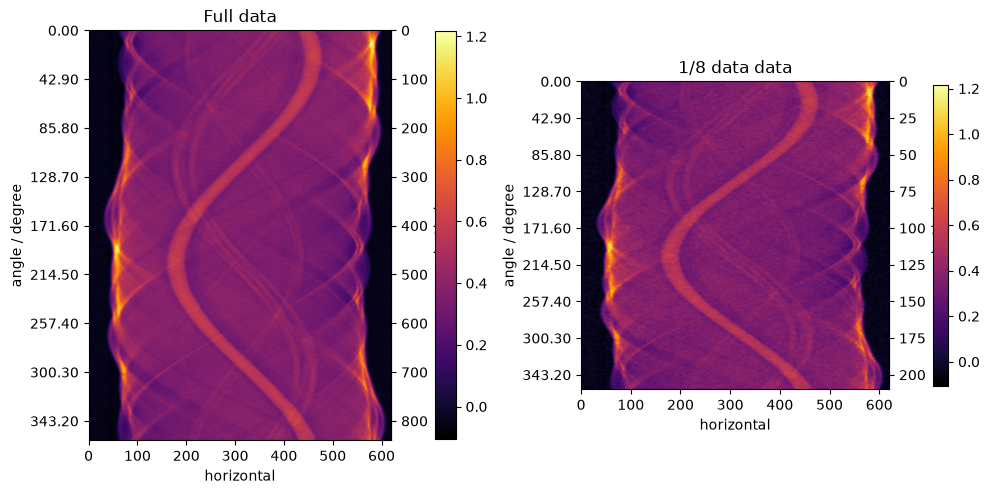

In [10]:
# Visualise data
show2D([full_data_slice, reduced_data_slice], ['Full data', '1/8 data data'], cmap=cmap, num_cols=2, size=(10,10), origin='upper-left', fix_range=True)

## CT reconstruction
Tomographic reconstruction consists of resolving the three-dimensional photon attenuation map of a scanned object from the collection of projection measurement. There are two major classes of reconstruction algorithms: *analytic* and *iterative*. 

### FBP

The FBP algorithm is implemented as a `Processor` which is set up with an `AcquisitionGeometry` and an `ImageGeometry`. You then can call your configured FBP processor  on an `AcquisitionData` object. The processor returns the reconstructed `ImageData`.

In [11]:
image_geometry = full_data_slice.geometry.get_ImageGeometry()

# reconstruct full and reduced data with FBP
recon_fbp_full = FBP(full_data_slice, image_geometry).run()
recon_fbp_reduced = FBP(reduced_data_slice, image_geometry).run()

FBP recon

Input Data:
	angle: 840
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):



FBP recon

Input Data:
	angle: 210
	horizontal: 620

Reconstruction Volume:
	horizontal_y: 620
	horizontal_x: 620

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 11
	Filter_inplace: False
	Split processing: 0

Reconstructing in 1 chunk(s):



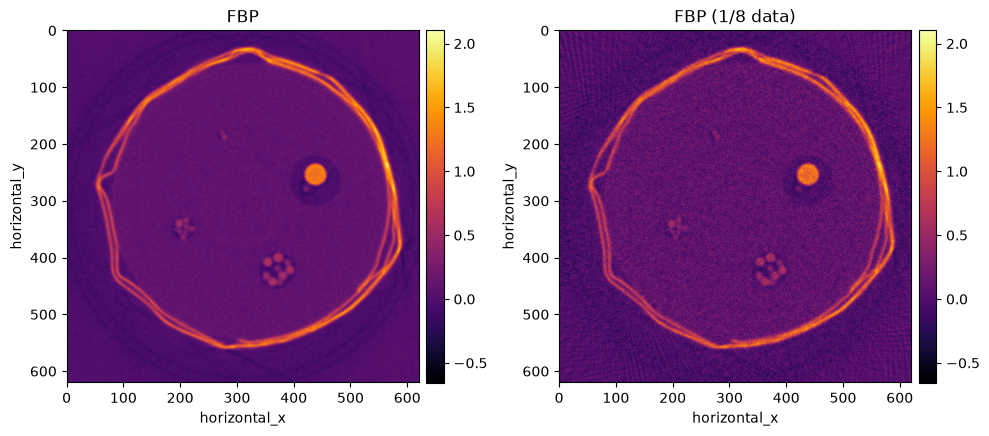

In [12]:
show2D([recon_fbp_full, recon_fbp_reduced], ['FBP', 'FBP (1/8 data)'], cmap=cmap, num_cols=2, size=(10,10), origin='upper-left', fix_range=True)

We know that outside the cylinder is just air so we can use a circular mask to remove some noise in the background. Then when we are comparing the reconstructions the results won't be skewed by the background.

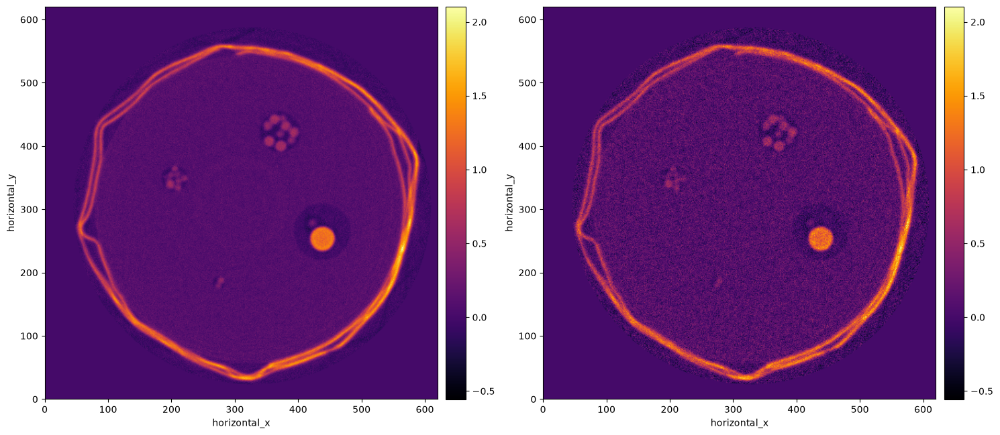

In [13]:
# circular mask applied to reconstructions: centre in pixels (row, col) and radius as a fraction of the half-size
MASK_CENTRE_PX = [305, 327]
MASK_RADIUS = 0.91


masked_fbp_full = create_circular_mask(recon_fbp_full, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
masked_fbp_reduced = create_circular_mask(recon_fbp_reduced, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
show2D([masked_fbp_full, masked_fbp_reduced], cmap=cmap, fix_range=True)

<a id='cgls'></a>
We set up the FISTA Algorithm with Total Variation Regularisation and a non-negativity constraint.
We set it up with a range of alpha values.
Note: to begin with we performed a wider sweep of alpha values:
[1e-6, 1e-4, 1e-2, 1] to get an idea of where to do a finer sweep of alphas.

In [14]:
alphas = [1e-4, 1e-3,5e-3, 1e-1]
fista_nn_algos = {alpha: None for alpha in alphas}
gr_slice = full_data_slice
# --- build unconstrained fista algorithms ---
for alpha in alphas:
    A = ProjectionOperator(gr_slice.geometry.get_ImageGeometry(), gr_slice.geometry)
    b = gr_slice
    F = LeastSquares(A, b)
    ig = gr_slice.geometry.get_ImageGeometry()
    GTV = alpha*FGP_TV(device='gpu') 
    initial = ig.allocate(0.0)
    myFISTANN = FISTA(f=F, 
                g=GTV,  initial=initial,
                update_objective_interval = 10)

    fista_nn_algos[alpha] = myFISTANN

We run each algorithm for a maximum of 1000 iterations but use a stopping rule based on change in objective value to determine whether convergence has been reached. If the objective value changes by less than our threshold of 1e-5 then the algorithm will stop iterating:

In [15]:
iteration_nums = 1000

for alpha, fista in fista_nn_algos.items():
    fista.run(iteration_nums, callbacks=[ProgressCallback(), EarlyStoppingObjectiveValue(threshold=1e-5)])

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [16]:
def title_with_metrics(name, reference, image):
    """Plot title with SSIM and L2NE of `image` compared to `reference` (both 2D ImageData)."""
    ref = reference.as_array()
    ssim_value = ssim(ref, image.as_array(), data_range=ref.max() - ref.min())
    l2_error = calculate_L2Norm_error(reference, image)
    return '{}, SSIM: {:.3f}, L2NE: {:.4f}'.format(name, ssim_value, l2_error)


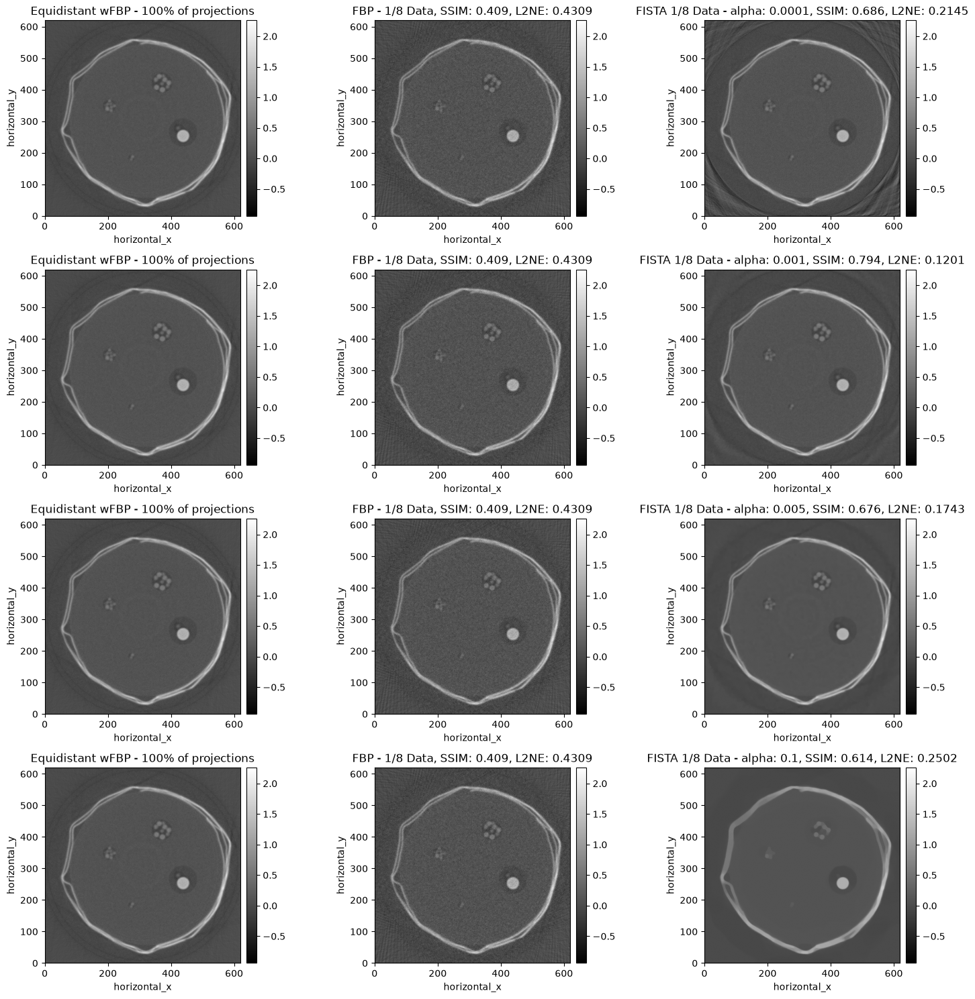

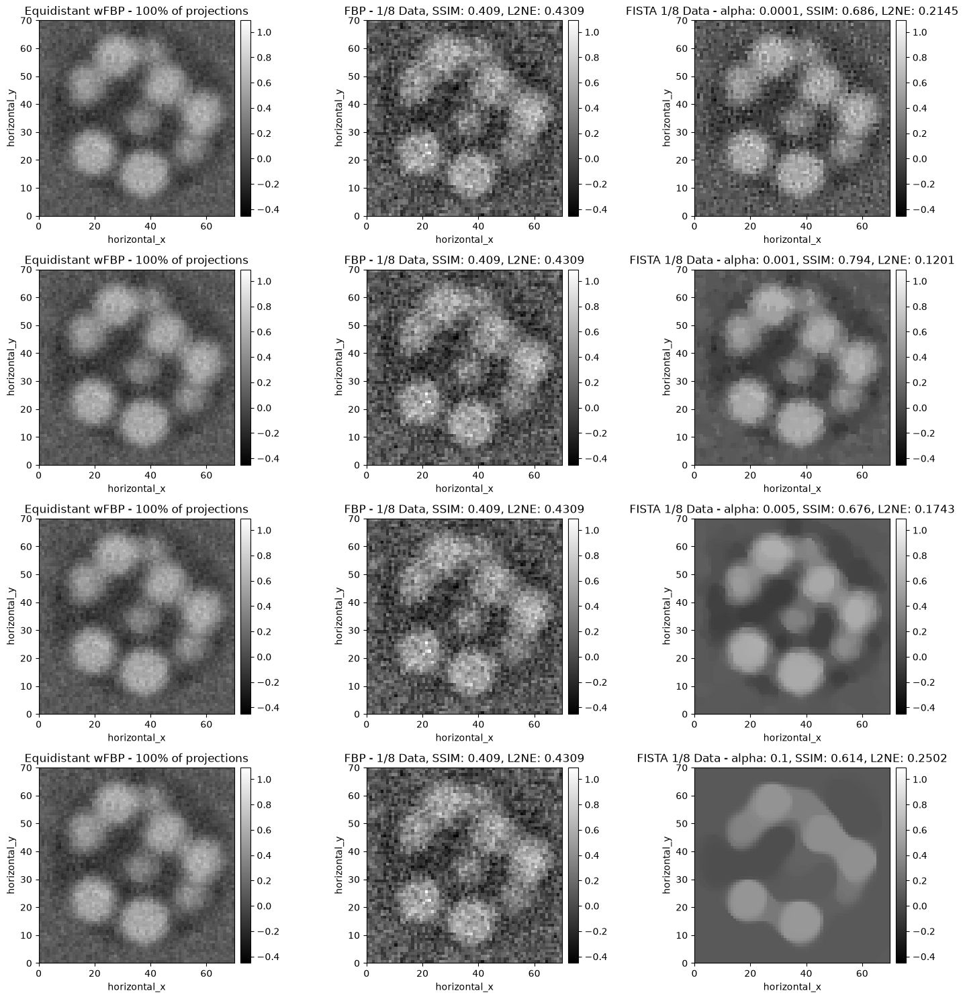

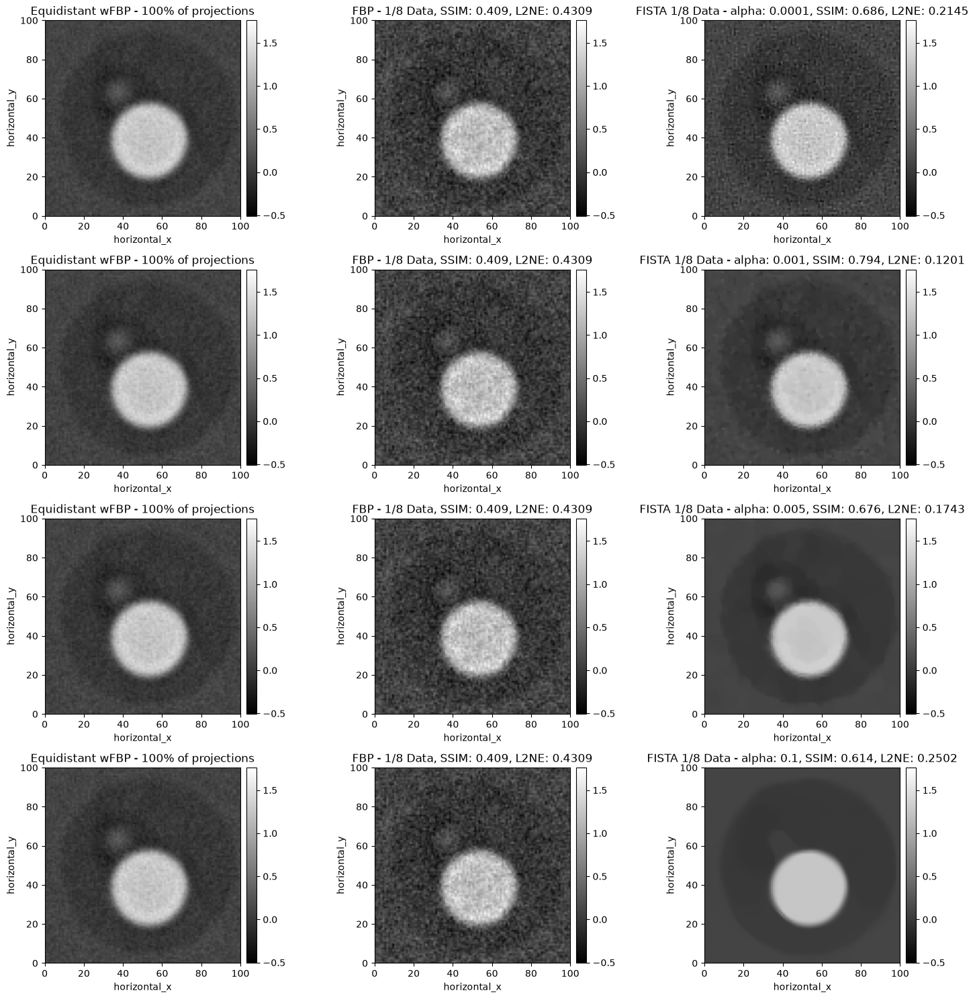

In [17]:
slicers = [None, Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)}), Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})]
for slicer in slicers:
    fista_titles = [f"FISTA 1/8 Data - alpha: {alpha}" for alpha in alphas]
    fista_results = [fista_nn_algos[alpha].solution for alpha in alphas]
    fbp_titles = [f"FBP - 1/8 Data" for alpha in alphas]
    fbp_results = [recon_fbp_reduced]*len(alphas)

    images = []
    titles = []
    zoomed_equi_recon = recon_fbp_full
    for alpha, fista_img, fista_title, fbp_img, fbp_title in zip(alphas, fista_results, fista_titles, fbp_results, fbp_titles):
        data_list = [zoomed_equi_recon, fbp_img, fista_img]
        if slicer is not None:
            data_list = [slicer(img) for img in data_list]
        images.extend(data_list)
        titles.extend([f"Equidistant wFBP - 100% of projections",
                    title_with_metrics(fbp_title, zoomed_equi_recon, fbp_img),
                    title_with_metrics(fista_title, zoomed_equi_recon, fista_img)])

    vmin = min(img.min() for img in images)
    vmax = max(img.max() for img in images)

    show2D(images, title=titles, cmap='gray', fix_range=(vmin, vmax), num_cols=3)

Compare with SIRT from before:

In [18]:
initial = image_geometry.allocate(0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 10

sirt.run(200)


  0%|          | 0/200 [00:00<?, ?it/s]

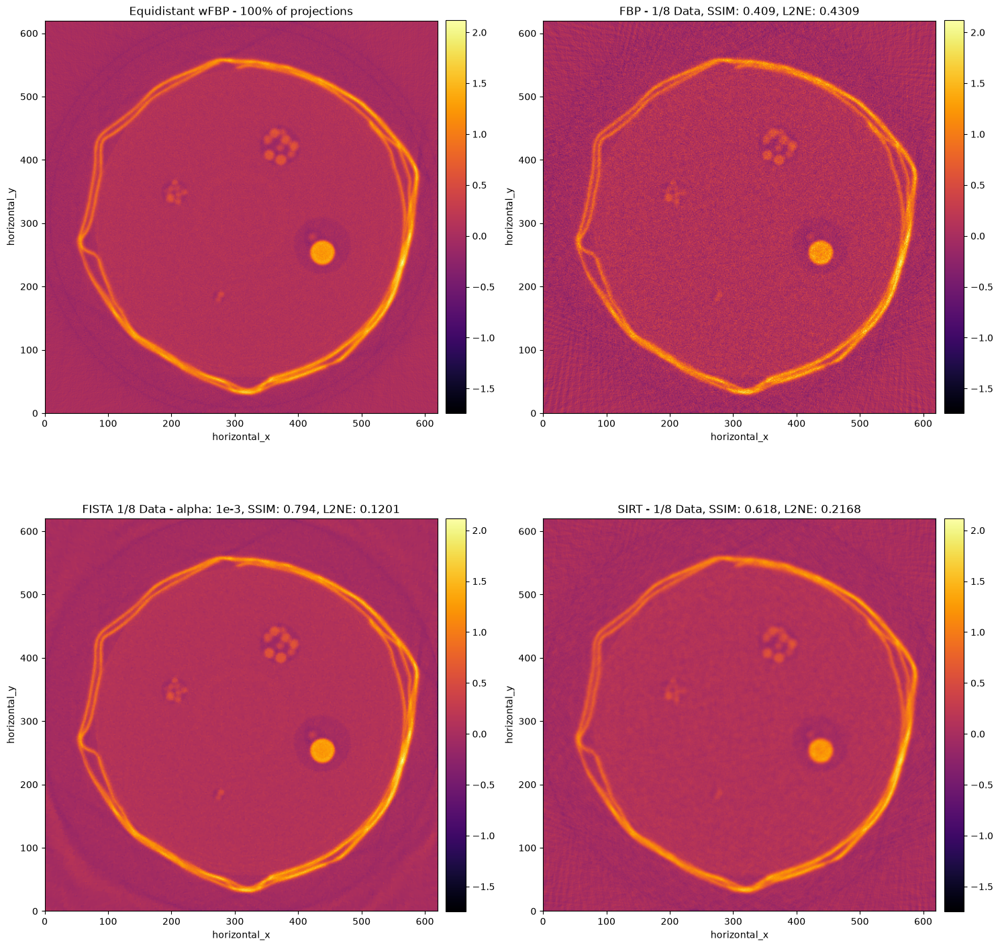

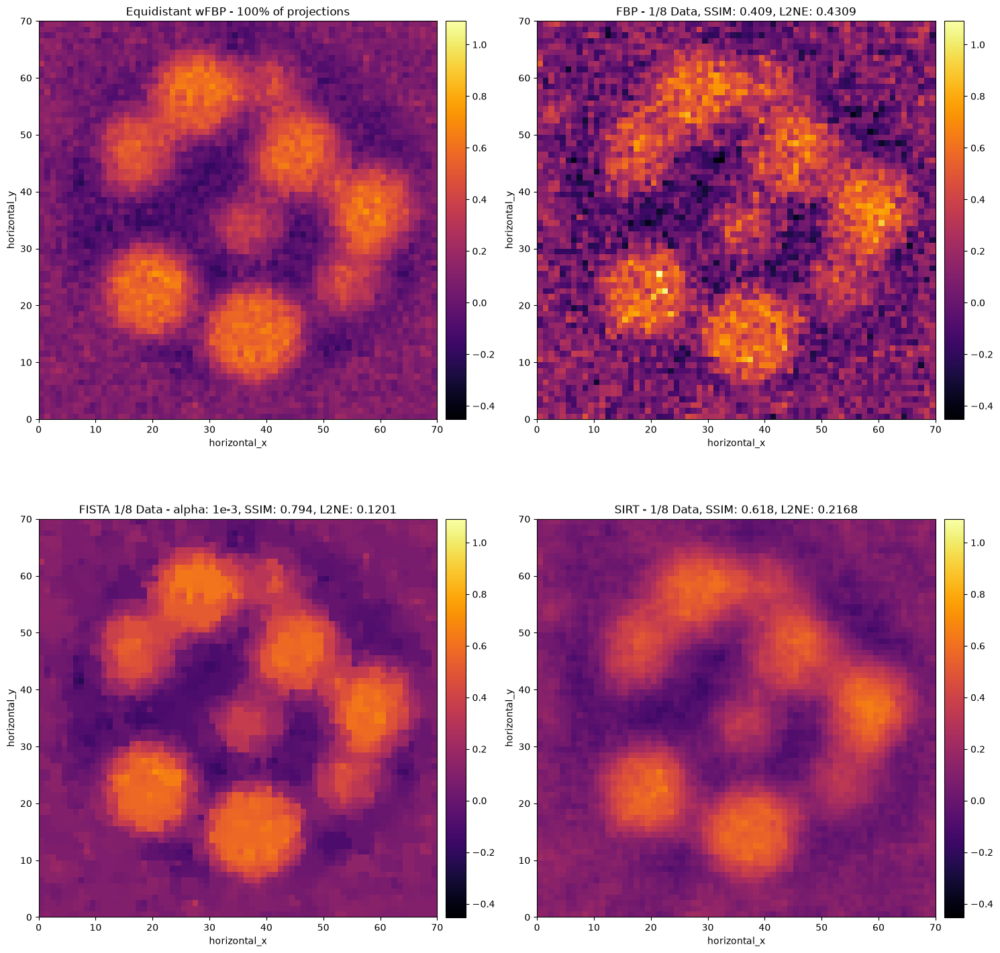

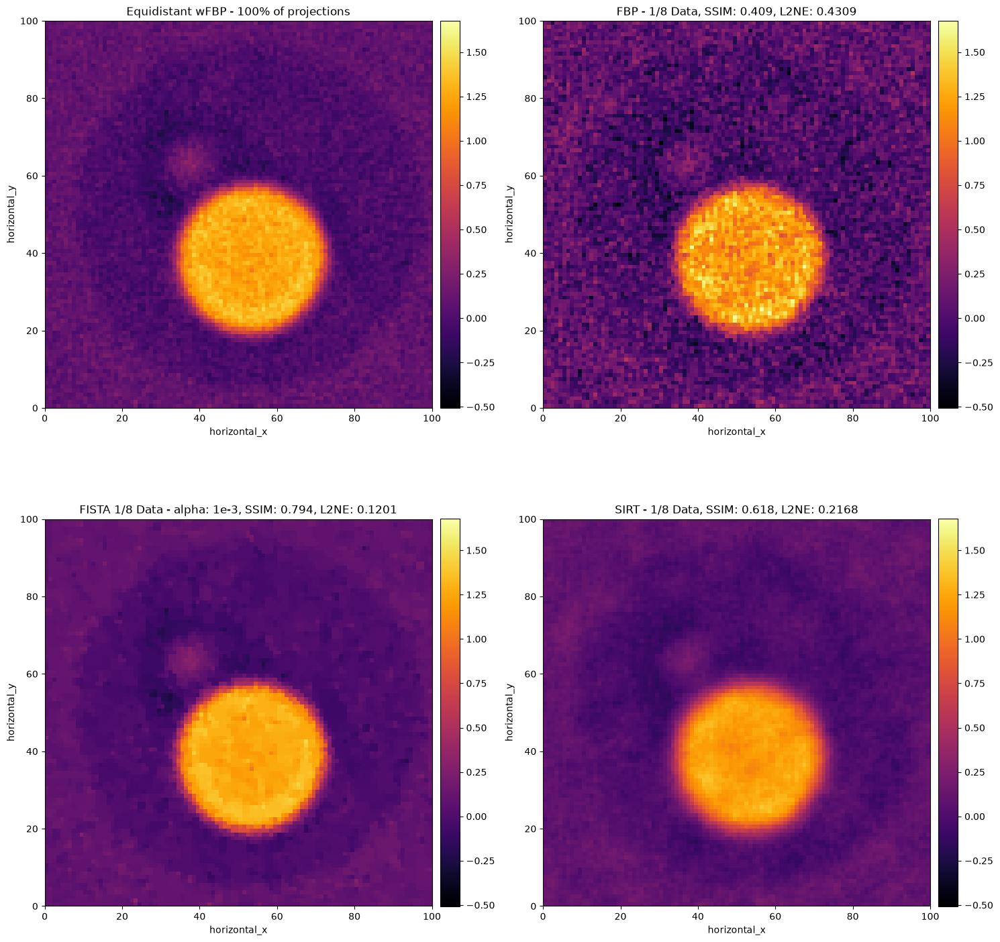

In [20]:

fista_img = fista_nn_algos[1e-3].solution
sirt_img = sirt.solution
fbp_img = recon_fbp_reduced
zoomed_equi_recon = recon_fbp_full
fbp_title = "FBP - 1/8 Data"
fista_title = "FISTA 1/8 Data - alpha: 1e-3"
sirt_title = "SIRT - 1/8 Data"

for slicer in slicers:
    images = []
    titles = []
    data_list = [zoomed_equi_recon, fbp_img, fista_img, sirt_img]
    if slicer is not None:
        data_list = [slicer(img) for img in data_list]
    images.extend(data_list)
    titles.extend([f"Equidistant wFBP - 100% of projections",
                title_with_metrics(fbp_title, zoomed_equi_recon, fbp_img), 
                title_with_metrics(fista_title, zoomed_equi_recon, fista_img),
                title_with_metrics(sirt_title, zoomed_equi_recon, sirt_img)])

    vmin = min(img.min() for img in images)
    vmax = max(img.max() for img in images)

    show2D(images, title=titles, cmap='inferno', fix_range=True, num_cols=2)

Let's run the algorithm, and check its progress to the solution after every iteration.
We'll plot the current solution, the difference with the full FBP, and the difference with the previous iteration.

### L2Norm Error (L2N-E)
This metric assess the difference in pixel values between a reconstruction and the full FBP.
&nbsp;

Method:
&nbsp;

$$
\text{L2N-E} = \frac{\| \text{Recon} - \text{full FBP} \|_2}{\| \text{full FBP} \|_2}
$$
&nbsp;


NameError: name 'l2_errors' is not defined

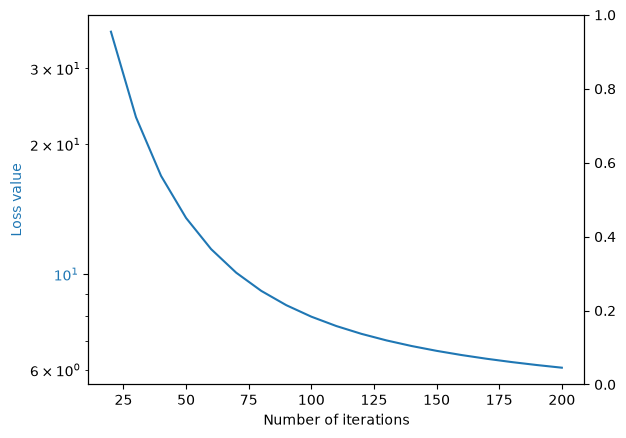

In [19]:
# print convergence:

fig, ax1 = plt.subplots()

# left axis: loss
ax1.plot(sirt.iterations[2:], sirt.loss[2:], color='tab:blue')
ax1.set_yscale('log')
ax1.set_xlabel('Number of iterations')
ax1.set_ylabel('Loss value', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# right axis: L2 norm error
ax2 = ax1.twinx()
ax2.plot(sirt.iterations[2:], l2_errors[1:], color='tab:orange')
ax2.set_ylabel('L2 norm error', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()


Iteration 200 is best

In [ ]:
initial = image_geometry.allocate(0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt = SIRT(initial=initial, operator=A, data=reduced_data_slice)
sirt.update_objective_interval = 10

sirt.run(200)

  0%|          | 0/200 [00:00<?, ?it/s]

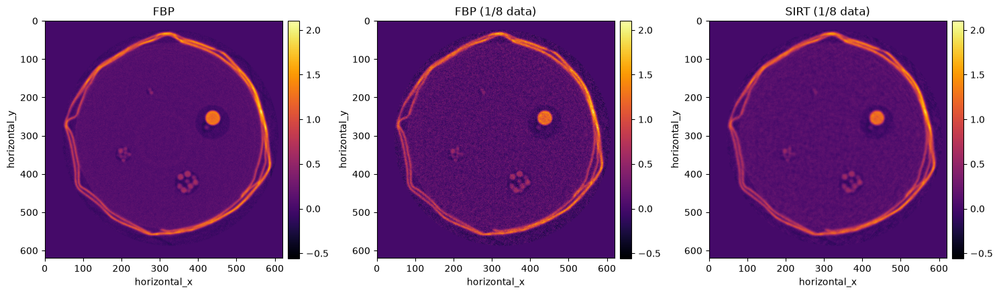

In [ ]:
recon_sirt = sirt.solution
masked_recon_sirt = create_circular_mask(sirt.solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)

show2D([masked_fbp_full, masked_fbp_reduced, masked_recon_sirt], ['FBP', 'FBP (1/8 data)', 'SIRT (1/8 data)'], \
       cmap=cmap, num_cols=3, size=(15,10), origin='upper-left', fix_range=True)

### Constrained reconstruction
Perhaps the most intuitive constraint one can enforce on reconstructed data is the non-negativity constraint. The image data we are reconstructing is the linear attenuation coefficient of the material, so intuitively this cannot have a negative value. Here we employ the SIRT algorithm,  an  algebraic  iterative  method  for  a particular weighted least-squares problem which in addition accepts certain convex constraints such as a non-negativity constraint. As with CGLS, it exhibits semi-convergence, however tends to require more iterations. We enforce box constraints (lower and upper bounds) with the `IndicatorBox` function.

In [ ]:
# initial estimate - zero array in this case 
initial = image_geometry.allocate(0)

constraint = IndicatorBox(lower=0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt_nn = SIRT(initial=initial, operator=A, data=reduced_data_slice, constraint=constraint)
sirt_nn.update_objective_interval = 10


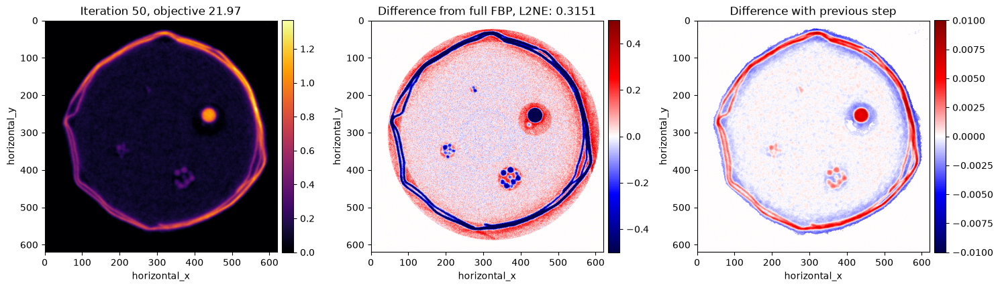

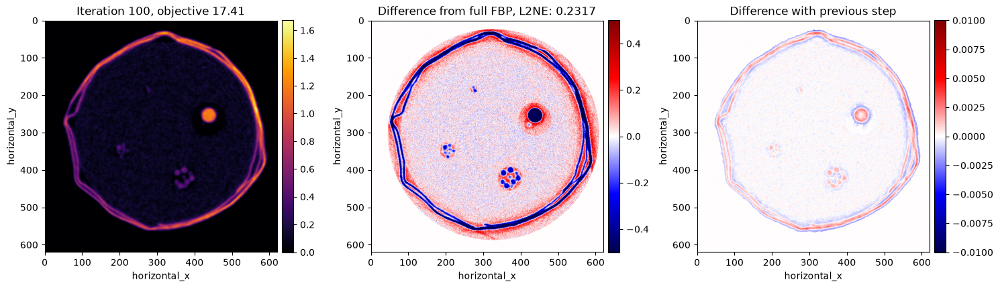

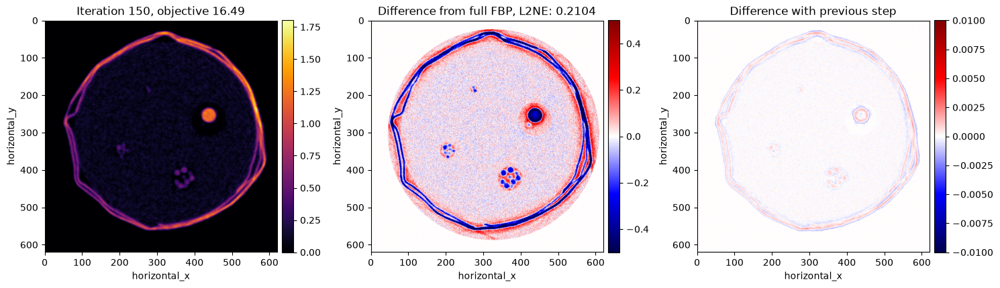

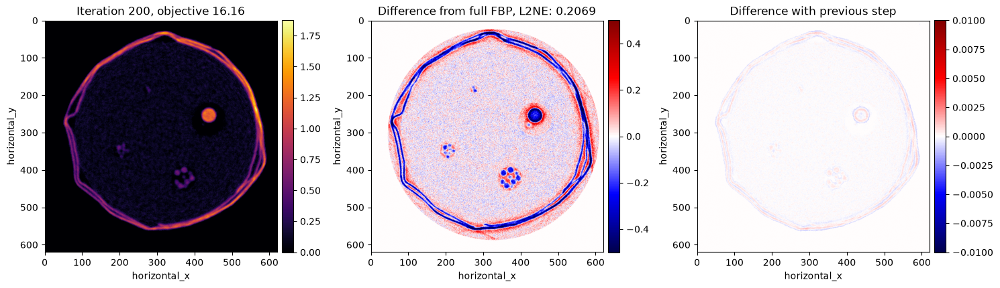

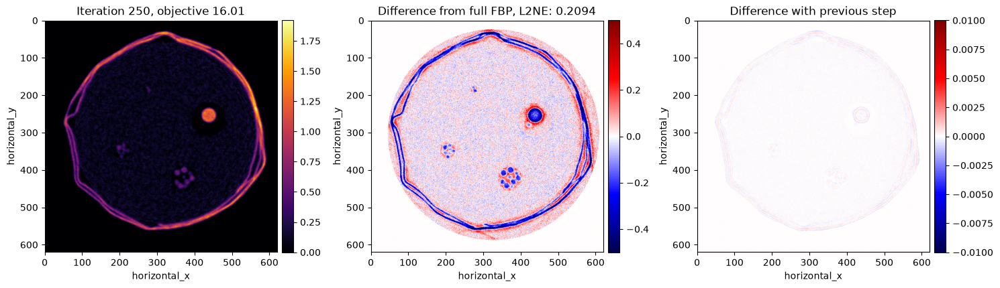

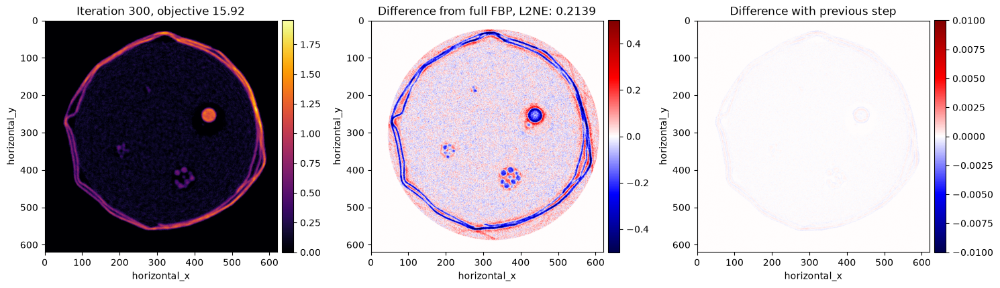

In [ ]:
# colormaps for the 3-panel SIRT progress plots: gray for the solution, seismic (symmetric) for the differences
cmaps = [cmap, 'seismic', 'seismic']
# fixed ranges for those plots, the differences are centred on 0
ranges = [None, (-0.5, 0.5), (-0.01, 0.01)]

diffs_from_full_fbp = []
l2_errors = []

for i in range(6):
    for j in range(5):
        sirt_nn.run(9, verbose=0, callbacks=[])
        previous = sirt_nn.solution.copy()
        sirt_nn.run(1, verbose=0, callbacks=[])

        # get and visualise the results
        masked_sirt_nn = create_circular_mask(sirt_nn.solution, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
        diffs_from_full_fbp.append(masked_sirt_nn - masked_fbp_full)

        l2_error = calculate_L2Norm_error(masked_fbp_full, masked_sirt_nn)
        l2_errors.append(l2_error)

    #use show2D to display the 3 plots with there own colour map and ranges
    show2D([sirt_nn.solution, diffs_from_full_fbp[i], sirt_nn.solution - previous],
        ["Iteration {}, objective {:.2f}".format(sirt_nn.iteration, sirt_nn.loss[-1]),
         "Difference from full FBP, L2NE: {:.4f}".format(l2_error),
         "Difference with previous step"], fix_range=ranges,
        cmap=cmaps, origin='upper-left', num_cols=3)


200 iters

In [ ]:
initial = image_geometry.allocate(0)

constraint = IndicatorBox(lower=0)

A = ProjectionOperator(image_geometry, reduced_data_slice.geometry, device=device)

sirt_nn = SIRT(initial=initial, operator=A, data=reduced_data_slice, constraint=constraint)
sirt_nn.update_objective_interval = 10
sirt_nn.run(200)

  0%|          | 0/200 [00:00<?, ?it/s]

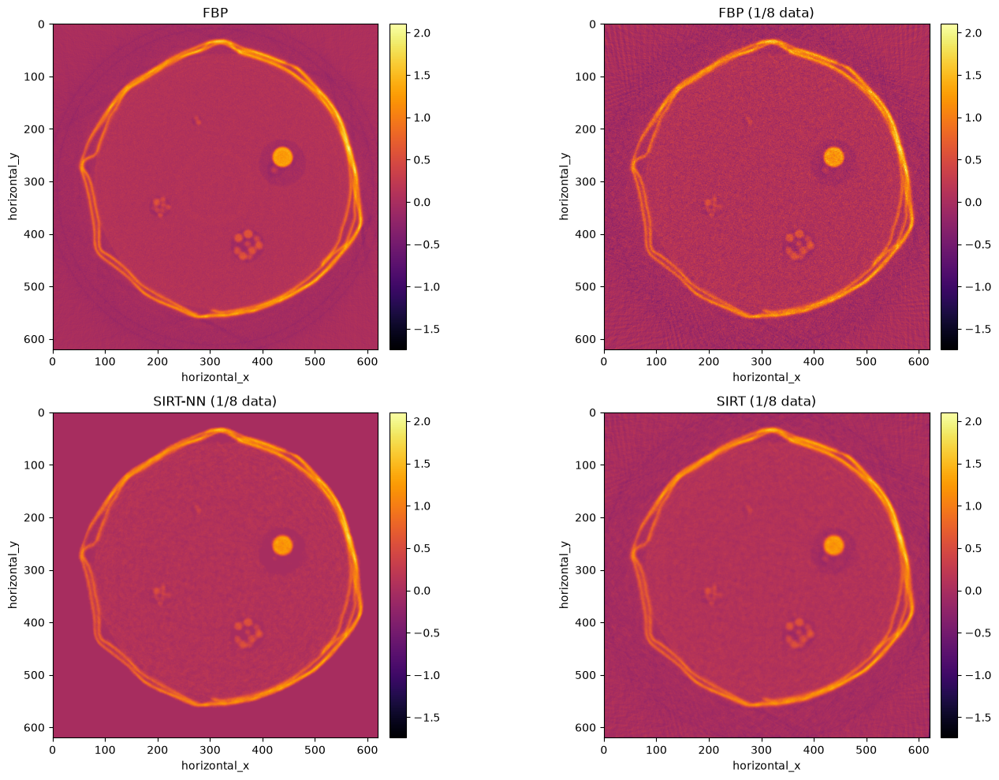

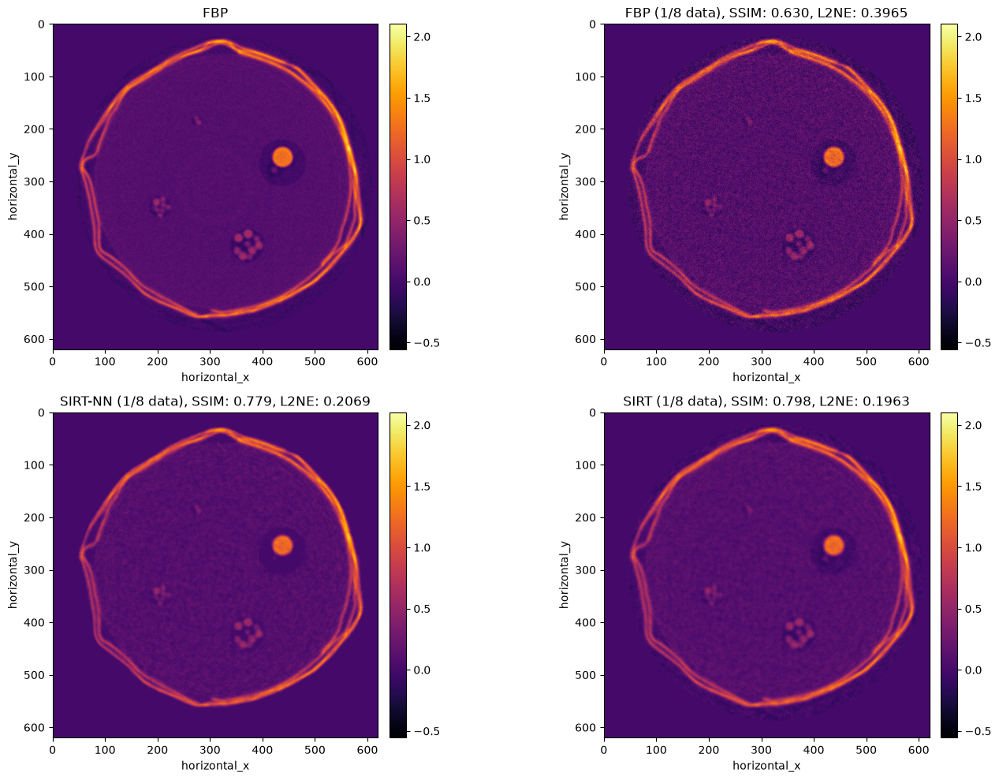

In [ ]:
def title_with_metrics(name, reference, image):
    """Plot title with SSIM and L2NE of `image` compared to `reference` (both 2D ImageData)."""
    ref = reference.as_array()
    ssim_value = ssim(ref, image.as_array(), data_range=ref.max() - ref.min())
    l2_error = calculate_L2Norm_error(reference, image)
    return '{}, SSIM: {:.3f}, L2NE: {:.4f}'.format(name, ssim_value, l2_error)

recon_sirt_nn = sirt_nn.solution
recon_titles = ['FBP',
                'FBP (1/8 data)',
                'SIRT-NN (1/8 data)',
                'SIRT (1/8 data)']
show2D([recon_fbp_full, recon_fbp_reduced, recon_sirt_nn, recon_sirt], recon_titles, \
       cmap=cmap, num_cols=2, size=(15,10), origin='upper-left', fix_range=True)

masked_sirt_nn = create_circular_mask(recon_sirt_nn, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)
masked_sirt = create_circular_mask(recon_sirt, MASK_CENTRE_PX, radius=MASK_RADIUS, in_place=False)

masked_titles = ['FBP',
                 title_with_metrics('FBP (1/8 data)', masked_fbp_full, masked_fbp_reduced),
                 title_with_metrics('SIRT-NN (1/8 data)', masked_fbp_full, masked_sirt_nn),
                 title_with_metrics('SIRT (1/8 data)', masked_fbp_full, masked_sirt)]
show2D([masked_fbp_full, masked_fbp_reduced, masked_sirt_nn, masked_sirt], masked_titles, \
       cmap=cmap, num_cols=2, size=(15,10), origin='upper-left', fix_range=True)

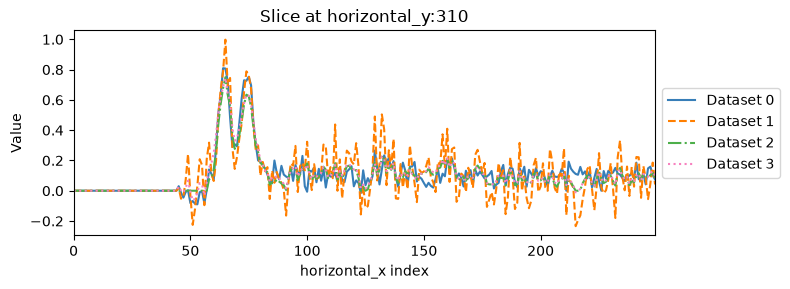

In [ ]:
slices = []

for x in [masked_fbp_full, masked_fbp_reduced, masked_sirt_nn, masked_sirt]:
    slices.append(Slicer(roi={'horizontal_x': (0,250)})(x))

show1D(slices, slice_list=[ ('horizontal_y', 310)])

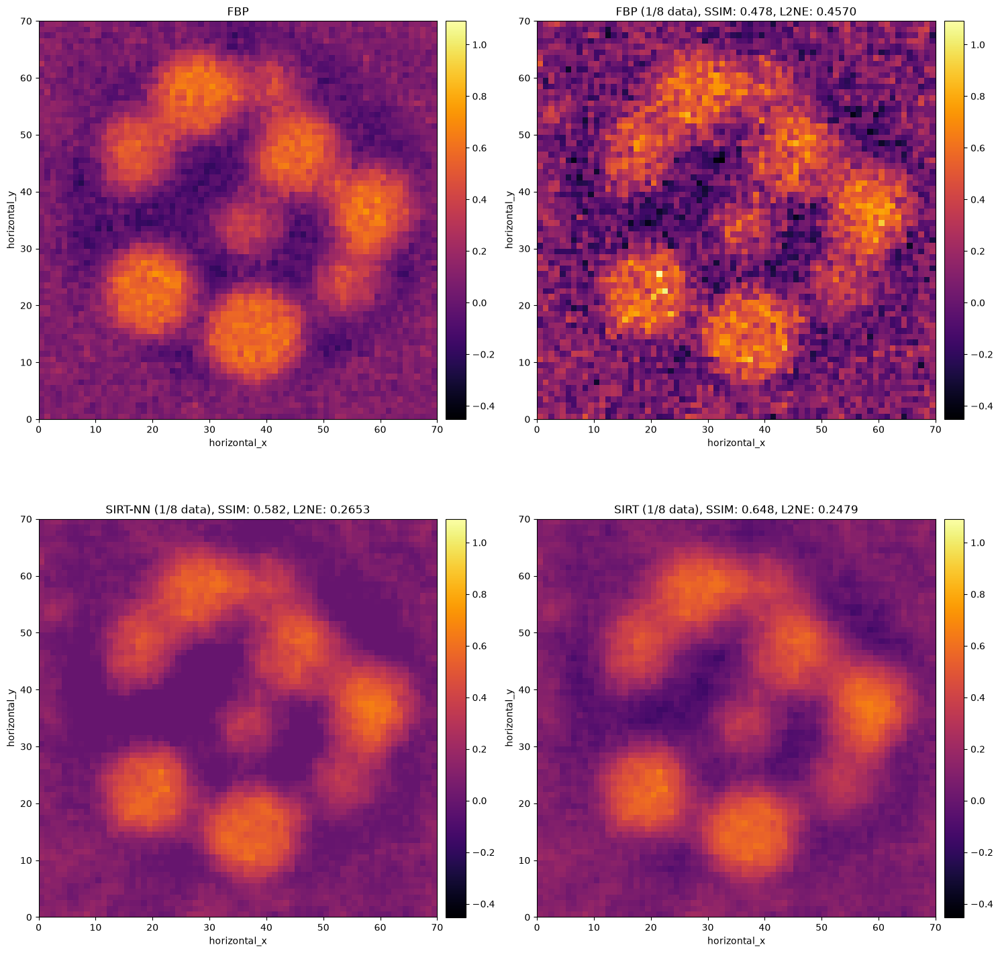

In [ ]:
multiple_beads_slicer = Slicer(roi={'horizontal_x': (335, 405), 'horizontal_y': (385, 455)})
rod_rois_full = multiple_beads_slicer(masked_fbp_full)
rod_rois_reduced = multiple_beads_slicer(masked_fbp_reduced)
rod_rois_sirt_nn = multiple_beads_slicer(masked_sirt_nn)
rod_rois_sirt = multiple_beads_slicer(masked_sirt)

show2D([x for x in [rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt]], fix_range=True, cmap=cmap, title=['FBP', title_with_metrics('FBP (1/8 data)', rod_rois_full, rod_rois_reduced), title_with_metrics('SIRT-NN (1/8 data)', rod_rois_full, rod_rois_sirt_nn), title_with_metrics('SIRT (1/8 data)', rod_rois_full, rod_rois_sirt)])

In [ ]:
large_and_small_slicer = Slicer(roi={'horizontal_x': (385, 485), 'horizontal_y': (215, 315)})

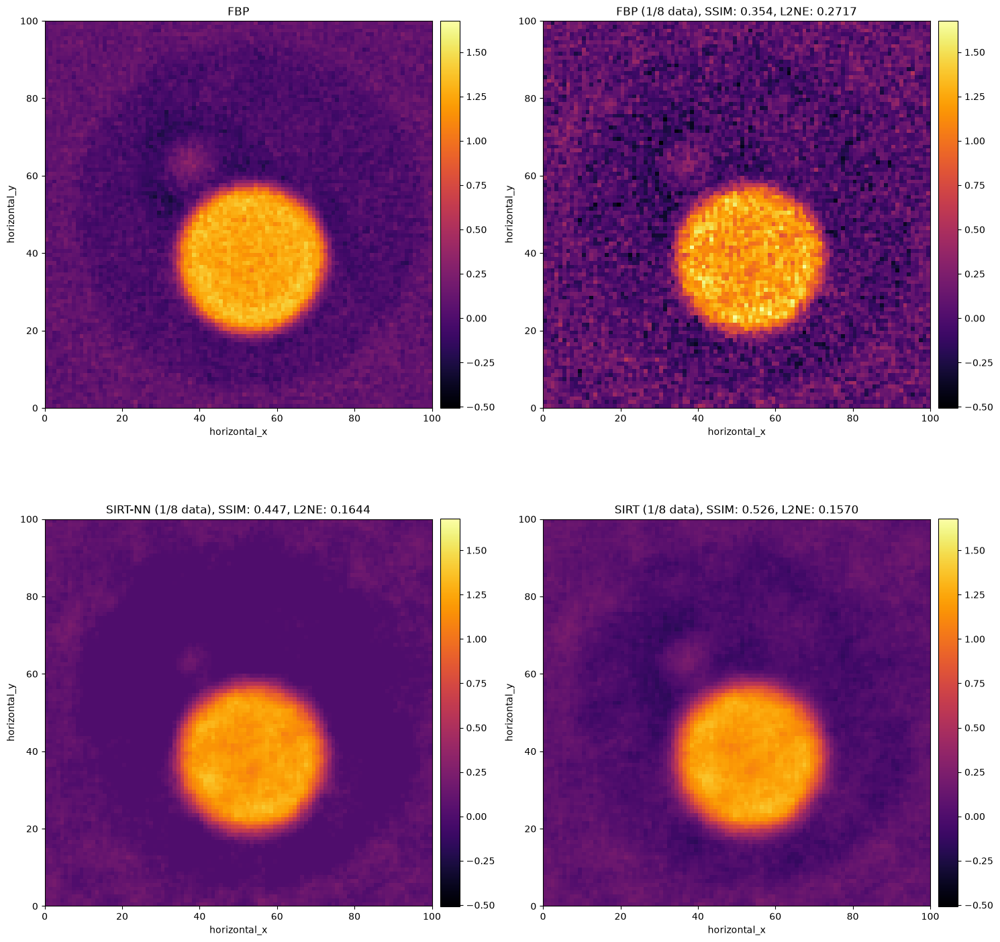

In [ ]:
rod_rois_full = large_and_small_slicer(masked_fbp_full)
rod_rois_reduced = large_and_small_slicer(masked_fbp_reduced)
rod_rois_sirt_nn = large_and_small_slicer(masked_sirt_nn)
rod_rois_sirt = large_and_small_slicer(masked_sirt)

show2D([x for x in [rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt]], fix_range=True, cmap=cmap, title=['FBP', title_with_metrics('FBP (1/8 data)', rod_rois_full, rod_rois_reduced), title_with_metrics('SIRT-NN (1/8 data)', rod_rois_full, rod_rois_sirt_nn), title_with_metrics('SIRT (1/8 data)', rod_rois_full, rod_rois_sirt)])

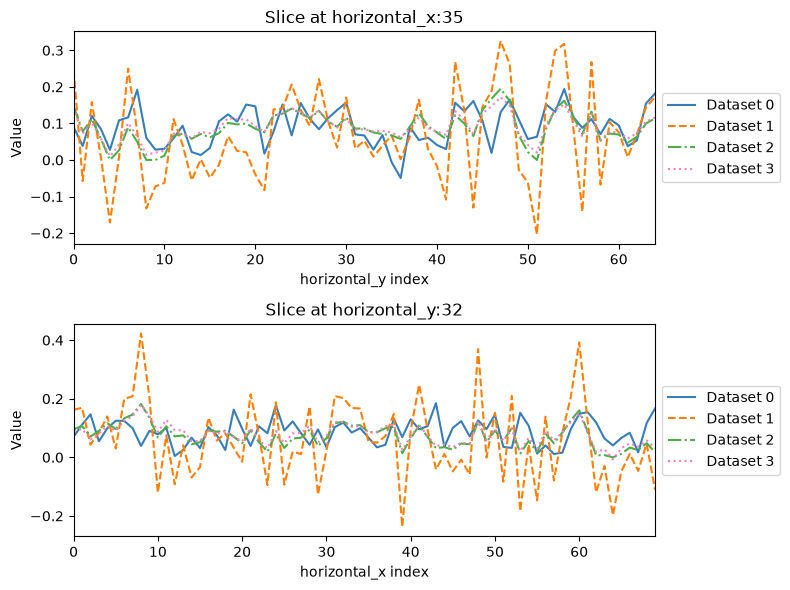

In [ ]:
show1D([x[2] for x in [rod_rois_full, rod_rois_reduced, rod_rois_sirt_nn, rod_rois_sirt]])